# Assignment 5 - S7 Conservative Investment / Profitability

Profitable Swiss stocks with controlled investment growth, leverage, liquidity, and volatility.

## 1. Imports and Paths

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt


def find_course_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'market_data.parquet').exists() and (candidate / 'src').exists():
            return candidate
        nested = candidate / 'qpmwp-course'
        if (nested / 'data' / 'market_data.parquet').exists() and (nested / 'src').exists():
            return nested
    raise FileNotFoundError('Could not locate qpmwp-course.')


COURSE_ROOT = find_course_root()
DATA_PATH = COURSE_ROOT / 'data'
SRC_PATH = COURSE_ROOT / 'src'

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print('COURSE_ROOT:', COURSE_ROOT)
print('DATA_PATH:', DATA_PATH)

COURSE_ROOT: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course
DATA_PATH: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/data


In [2]:
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from optimization.optimization import Optimization, Objective
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)

## 2. Data

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3. Parameters

In [4]:
N_MONTHS = 3
START_DATE = '2003-01-01'

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000
FUNDAMENTAL_LAG_DAYS = 90
FUNDAMENTAL_LOOKBACK_DAYS = 580
RISK_LOOKBACK_DAYS = 252 * 2

OPERATING_PROFITABILITY_FIELDS = ['op_at', 'cop_at', 'gp_at']
PROFITABILITY_SCORE_FIELDS = ['op_at', 'cop_at', 'gp_at', 'qmj_prof']
INVESTMENT_FIELDS = ['at_gr1', 'inv_gr1', 'inv_gr1a', 'ppeinv_gr1a']
LEVERAGE_FIELDS = ['debt_me', 'netdebt_me']
QUALITY_FIELDS = ['qmj', 'f_score']
SCORE_FIELDS = sorted(set(PROFITABILITY_SCORE_FIELDS + INVESTMENT_FIELDS + LEVERAGE_FIELDS + QUALITY_FIELDS))
FRESHNESS_FIELDS = SCORE_FIELDS

MIN_POSITIVE_PROFITABILITY_FIELDS = 2
MIN_PROFITABILITY_PERCENTILE = 0.25
MAX_INVESTMENT_PERCENTILE = 0.75
MAX_LEVERAGE_PERCENTILE = 0.85
MIN_QUALITY_PERCENTILE = 0.20
MAX_VOL_PERCENTILE = 0.90
MAX_STOCK_WEIGHT = 0.18

print('Profitability fields:', OPERATING_PROFITABILITY_FIELDS)
print('Investment fields:', INVESTMENT_FIELDS)

Profitability fields: ['op_at', 'cop_at', 'gp_at']
Investment fields: ['at_gr1', 'inv_gr1', 'inv_gr1a', 'ppeinv_gr1a']


## 4. Builder Functions

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def latest_lagged_jkp(bs, rebdate, fields, lag_days=90, lookback_days=580):
    fields = [field for field in fields if field in bs.data.jkp_data.columns]
    if not fields:
        raise ValueError('None of the requested JKP fields exist in jkp_data.')

    cutoff = pd.to_datetime(rebdate) - pd.Timedelta(days=lag_days)
    start = cutoff - pd.Timedelta(days=lookback_days)
    dates = bs.data.jkp_data.index.get_level_values('date')
    window = bs.data.jkp_data.loc[(dates <= cutoff) & (dates >= start), fields]
    return window.groupby(level='id').last()


def rank_mean(df, fields=None, high_is_good=True):
    if fields is not None:
        fields = [field for field in fields if field in df.columns]
        df = df[fields]
    ranks = df.rank(pct=True)
    score = ranks.mean(axis=1)
    if not high_is_good:
        score = 1 - score
    return score


def conservative_score_from_latest(latest):
    profitability = rank_mean(latest, PROFITABILITY_SCORE_FIELDS, high_is_good=True)
    conservative_investment = rank_mean(latest, INVESTMENT_FIELDS, high_is_good=False)
    conservative_leverage = rank_mean(latest, LEVERAGE_FIELDS, high_is_good=False)
    quality = rank_mean(latest, QUALITY_FIELDS, high_is_good=True)

    score = (
        0.45 * profitability
        + 0.30 * conservative_investment
        + 0.15 * conservative_leverage
        + 0.10 * quality
    )
    return score.rank(pct=True)


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RETURN_HISTORY_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= kwargs.get('min_obs', MIN_RETURN_OBS)).astype(int),
    })


def bibfn_selection_fundamental_freshness(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', FRESHNESS_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    non_missing = latest.notna().sum(axis=1)

    return pd.DataFrame({
        'values': non_missing,
        'binary': (non_missing >= 5).astype(int),
    })


def bibfn_selection_positive_profitability(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', OPERATING_PROFITABILITY_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    positive_count = latest.gt(0).sum(axis=1)

    return pd.DataFrame({
        'values': positive_count,
        'binary': (positive_count >= kwargs.get('min_positive', MIN_POSITIVE_PROFITABILITY_FIELDS)).astype(int),
    })


def bibfn_selection_profitability_floor(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', PROFITABILITY_SCORE_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    score = rank_mean(latest, high_is_good=True)

    return pd.DataFrame({
        'values': score,
        'binary': score.ge(kwargs.get('min_percentile', MIN_PROFITABILITY_PERCENTILE)).fillna(False).astype(int),
    })


def bibfn_selection_conservative_investment(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', INVESTMENT_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    aggressive_growth = rank_mean(latest, high_is_good=True)

    return pd.DataFrame({
        'values': aggressive_growth,
        'binary': aggressive_growth.le(kwargs.get('max_percentile', MAX_INVESTMENT_PERCENTILE)).fillna(False).astype(int),
    })


def bibfn_selection_acceptable_leverage(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', LEVERAGE_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    leverage = rank_mean(latest, high_is_good=True)

    return pd.DataFrame({
        'values': leverage,
        'binary': leverage.le(kwargs.get('max_percentile', MAX_LEVERAGE_PERCENTILE)).fillna(False).astype(int),
    })


def bibfn_selection_quality_floor(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', QUALITY_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    quality = rank_mean(latest, high_is_good=True)

    return pd.DataFrame({
        'values': quality,
        'binary': quality.ge(kwargs.get('min_percentile', MIN_QUALITY_PERCENTILE)).fillna(False).astype(int),
    })


def bibfn_selection_volatility_cap(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RISK_LOOKBACK_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    vol = ret.std(axis=0) * np.sqrt(252)
    threshold = vol.quantile(kwargs.get('max_percentile', MAX_VOL_PERCENTILE))

    return pd.DataFrame({
        'values': vol,
        'binary': vol.le(threshold).fillna(False).astype(int),
    })


def bibfn_conservative_scores(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', SCORE_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = pd.Index(bs.selection.selected).astype(str)
    latest = latest.reindex(ids)
    score = conservative_score_from_latest(latest).reindex(ids)
    bs.optimization_data['conservative_score'] = score.fillna(score.median()).fillna(0.5)
    return None


def cap_and_redistribute(weights, cap):
    weights = weights.copy().astype(float)
    if weights.empty:
        return weights
    if len(weights) * cap < 1:
        return weights / weights.sum()

    free = pd.Index(weights.index)
    capped = pd.Series(0.0, index=weights.index)
    remaining = 1.0

    while len(free) > 0:
        scaled = weights.loc[free] / weights.loc[free].sum() * remaining
        over = scaled > cap
        if not over.any():
            capped.loc[free] = scaled
            break
        capped.loc[scaled[over].index] = cap
        remaining = 1.0 - capped.sum()
        free = scaled[~over].index

    return capped / capped.sum()


class ConservativeProfitabilityInverseVolPortfolio(Optimization):
    def __init__(self, max_weight=MAX_STOCK_WEIGHT, score_tilt=0.60, **kwargs):
        super().__init__(max_weight=max_weight, score_tilt=score_tilt, solver_name='no-solver-used', **kwargs)

    def set_objective(self, optimization_data):
        ret = optimization_data['return_series']
        ids = ret.columns
        vol = ret.std(axis=0) * np.sqrt(252)
        inv_vol = 1 / vol.replace(0, np.nan)
        score = optimization_data.get('conservative_score', pd.Series(0.5, index=ids)).reindex(ids).fillna(0.5)
        tilt = 1 + self.params['score_tilt'] * (score - 0.5)
        raw_weight = (inv_vol * tilt).dropna()
        self.objective = Objective(raw_weight=raw_weight)

    def solve(self):
        raw_weight = self.objective.coefficients['raw_weight']
        weights = raw_weight / raw_weight.sum()
        weights = cap_and_redistribute(weights, self.params['max_weight'])
        self.results.update({'weights': weights.to_dict(), 'status': True})
        return None


class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## 5. Rebalancing Dates

In [6]:
jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])

Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6. Backtest

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
    'fundamental_freshness': SelectionItemBuilder(
        bibfn=bibfn_selection_fundamental_freshness,
        fields=FRESHNESS_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'positive_profitability': SelectionItemBuilder(
        bibfn=bibfn_selection_positive_profitability,
        fields=OPERATING_PROFITABILITY_FIELDS,
        min_positive=MIN_POSITIVE_PROFITABILITY_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'profitability_floor': SelectionItemBuilder(
        bibfn=bibfn_selection_profitability_floor,
        fields=PROFITABILITY_SCORE_FIELDS,
        min_percentile=MIN_PROFITABILITY_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'conservative_investment': SelectionItemBuilder(
        bibfn=bibfn_selection_conservative_investment,
        fields=INVESTMENT_FIELDS,
        max_percentile=MAX_INVESTMENT_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'acceptable_leverage': SelectionItemBuilder(
        bibfn=bibfn_selection_acceptable_leverage,
        fields=LEVERAGE_FIELDS,
        max_percentile=MAX_LEVERAGE_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'quality_floor': SelectionItemBuilder(
        bibfn=bibfn_selection_quality_floor,
        fields=QUALITY_FIELDS,
        min_percentile=MIN_QUALITY_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'volatility_cap': SelectionItemBuilder(
        bibfn=bibfn_selection_volatility_cap,
        width=RISK_LOOKBACK_DAYS,
        max_percentile=MAX_VOL_PERCENTILE,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=RISK_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
    'conservative_score': OptimizationItemBuilder(
        bibfn=bibfn_conservative_scores,
        fields=SCORE_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
}

optimization = ConservativeProfitabilityInverseVolPortfolio(max_weight=MAX_STOCK_WEIGHT)

bs_s7 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=True,
)

bt_s7 = Backtest()
bt_s7.run(bs=bs_s7)

weights_s7 = bt_s7.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s7.shape)
print('Average holdings:', weights_s7.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s7.max(axis=1).mean().round(3))

Backtest completed.
Weight matrix: (85, 101)
Average holdings: 29.8
Average max stock weight: 0.065


## 7. Returns

In [8]:
return_series = data.get_return_series(weekdays_only=False)

s7_gross_returns = bt_s7.strategy.simulate(
    return_series=return_series,
    fc=0,
    vc=0,
)
s7_gross_returns.name = 'S7 gross'

s7_net_returns = bt_s7.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s7_net_returns.name = 'S7 net'

comparison = pd.concat(
    {
        'S7 net': s7_net_returns,
        'S7 gross': s7_gross_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)

2003-02-03 to 2024-04-30
           count      mean       std  ...       50%       75%       max
S7 net    5609.0  0.000372  0.009338  ...  0.000589  0.005275  0.083690
S7 gross  5609.0  0.000439  0.009339  ...  0.000635  0.005328  0.083809
SPI       5609.0  0.000332  0.009932  ...  0.000350  0.005263  0.105788

[3 rows x 8 columns]


/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


<ipython-input-1-e4b0e6297caf>:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


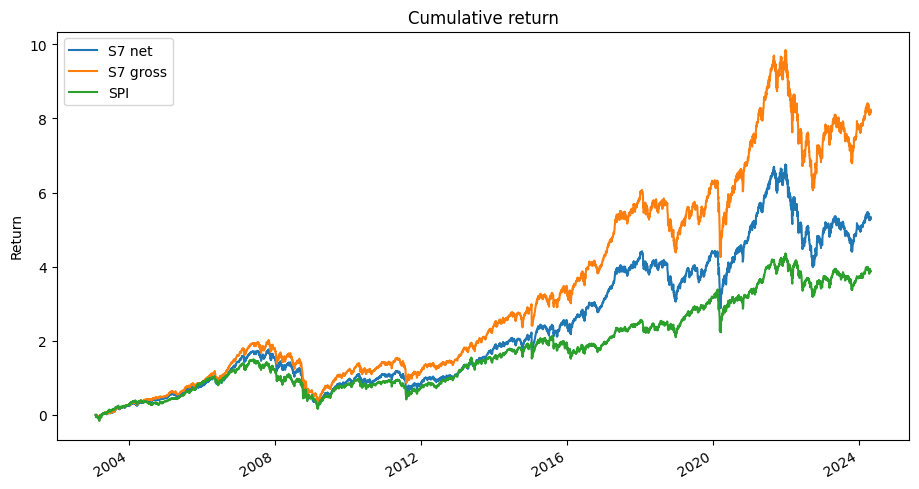

In [9]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Return')
plt.show()

<ipython-input-1-46ee3a3616a8>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


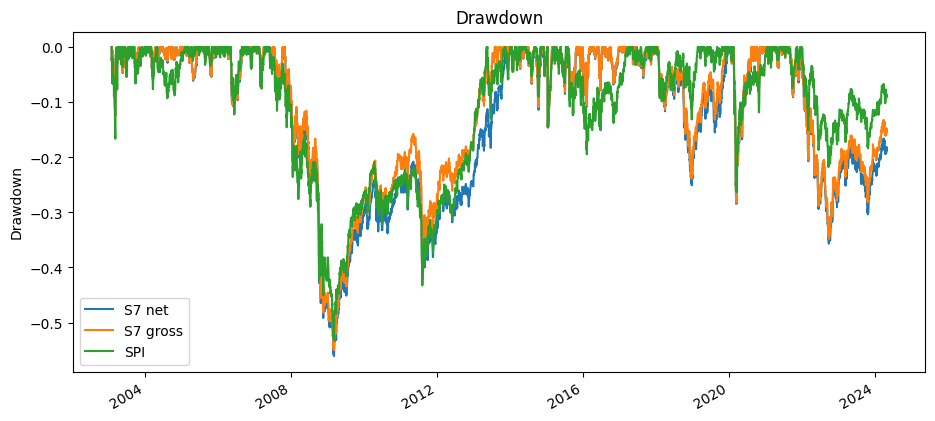

In [10]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    peak = wealth.cummax()
    return wealth / peak - 1


ax = drawdown(comparison).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
plt.show()

<ipython-input-1-fafb2b3115db>:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


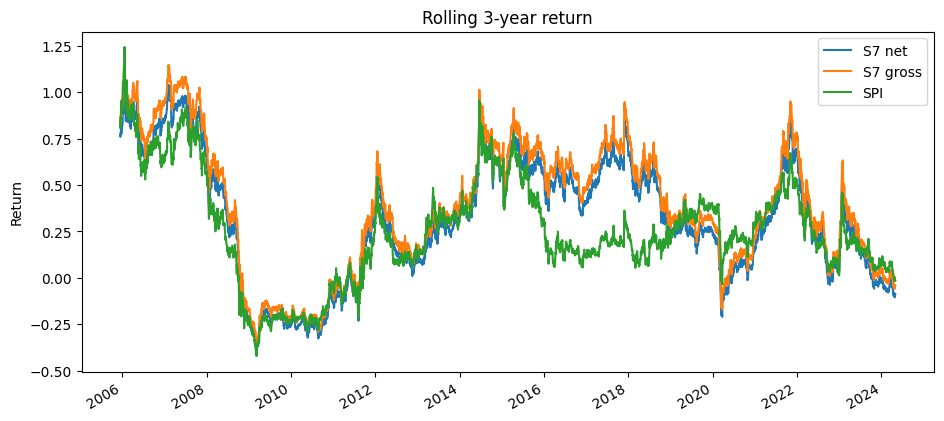

In [11]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return.plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Return')
plt.show()

## 8. Statistics

In [12]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

Out[0]: <pandas.io.formats.style.Styler at 0x11ea801d0>


In [13]:
turnover_s7 = bt_s7.strategy.turnover(return_series=return_series, rescale=False)

print('Average turnover:', turnover_s7.mean().round(3))
print('Median turnover:', turnover_s7.median().round(3))

turnover_s7.describe().to_frame('turnover')

Average turnover: 0.406
Median turnover: 0.417
Out[0]: 
        turnover
count  85.000000
mean    0.406123
std     0.150930
min     0.126389
25%     0.298337
50%     0.417320
75%     0.500752
max     1.000000


## 9. Selection Diagnostics

In [14]:
selection_counts = []

for rebdate in rebdates:
    bs_s7.build_selection(rebdate)
    binary = bs_s7.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()

Out[0]: 
            return_history  gaps  ...  volatility_cap  selected_after_all_filters
2023-01-31            48.0  48.0  ...            43.0                        43.0
2023-04-30            49.0  49.0  ...            44.0                        44.0
2023-07-31            41.0  41.0  ...            37.0                        37.0
2023-10-31            38.0  38.0  ...            34.0                        34.0
2024-01-31            37.0  37.0  ...            33.0                        33.0

[5 rows x 11 columns]


<ipython-input-1-db2bc1c382c8>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


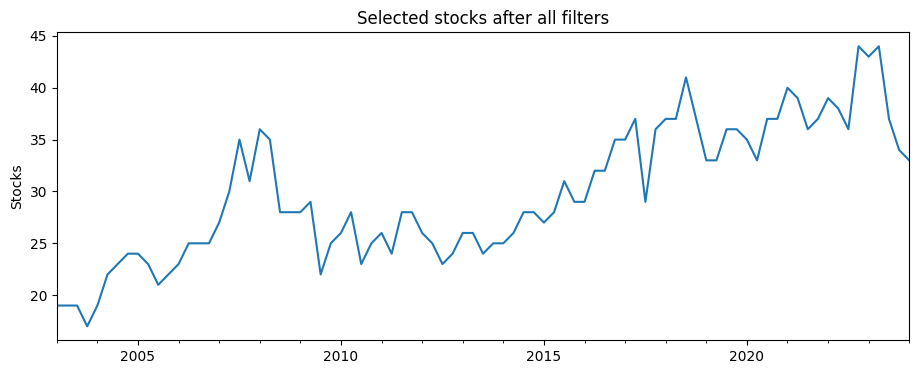

In [15]:
ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Selected stocks after all filters',
)
ax.set_ylabel('Stocks')
plt.show()

## 10. Summary

S7 keeps profitable firms with moderate investment growth and leverage. The portfolio tilts toward stronger profitability-investment scores while keeping position risk controlled through inverse-volatility weights.